# 결함 발생 후 센서 패턴 분석

이 노트북은 결함 시작 전 2시간을 기준선으로 두고, 결함 시작 후 최대 6시간 동안 센서가 어떻게 반응하는지 분석합니다.

주요 질문은 다음과 같습니다.

1. 결함 발생 직후 어떤 센서가 가장 먼저 변하는가?
2. 변화가 시간이 지나면서 커지는가, 유지되는가, 회복되는가?
3. 결함 유형별로 구분 가능한 패턴이 있는가?
4. 전력 소비량은 결함 발생 직후 증가하는가?

결함이 6시간 전에 끝난 이벤트는 종료 이후 값을 해당 결함의 패턴 집계에서 제외합니다. 따라서 회복된 정상 구간이 결함 패턴에 섞이지 않습니다.


## 0. 데이터 로드

실시간 전처리 파일을 사용합니다. 센서 결측은 반응기별 과거 값으로 최대 6분까지만 채워졌으며 미래 값은 사용하지 않았습니다.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 190)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize":(12,5),"font.family":"Nanum Gothic","axes.unicode_minus":False,"font.size":9})

DATA_PATH = Path("data/processed/chemical_process_timeseries_realtime_ffill.csv.gz")
if not DATA_PATH.exists(): DATA_PATH = Path("../data/processed/chemical_process_timeseries_realtime_ffill.csv.gz")

sensor_cols = [
    "reactor_temp", "reactor_pressure", "feed_flow_rate", "coolant_flow_rate",
    "agitator_speed_rpm", "reaction_rate", "conversion_rate", "selectivity",
    "yield_pct", "vibration_rms", "motor_current", "power_consumption_kw",
]
use_cols = ["timestamp","operating_regime","reactor_id","fault_type"] + sensor_cols
df = pd.read_csv(DATA_PATH, usecols=use_cols, parse_dates=["timestamp"])
df = df.sort_values(["reactor_id","timestamp"]).reset_index(drop=True)

fault_names = {1:"F1 냉각 성능 저하",2:"F2 원료 유량 막힘",3:"F3 센서 드리프트",4:"F4 기계 마모"}
colors = {1:"#e76f51",2:"#457b9d",3:"#8a5a9e",4:"#2a9d8f"}
print(f"데이터: {len(df):,}행, 센서 {len(sensor_cols)}개")


데이터: 777,600행, 센서 12개


## 1. 결함 이벤트와 지속시간

같은 반응기에서 결함 유형이 바뀌는 연속 구간을 하나의 이벤트로 정의합니다. 결함 지속시간이 6시간보다 짧을 수 있으므로 시간별 활성 이벤트 수를 함께 확인합니다.


             event_count  min_min  median_min  max_min
fault_name                                            
F1 냉각 성능 저하           10      308     953.500     1310
F2 원료 유량 막힘            9      202     841.000     1225
F3 센서 드리프트             7      266     559.000     1301
F4 기계 마모               9      325     672.000     1417


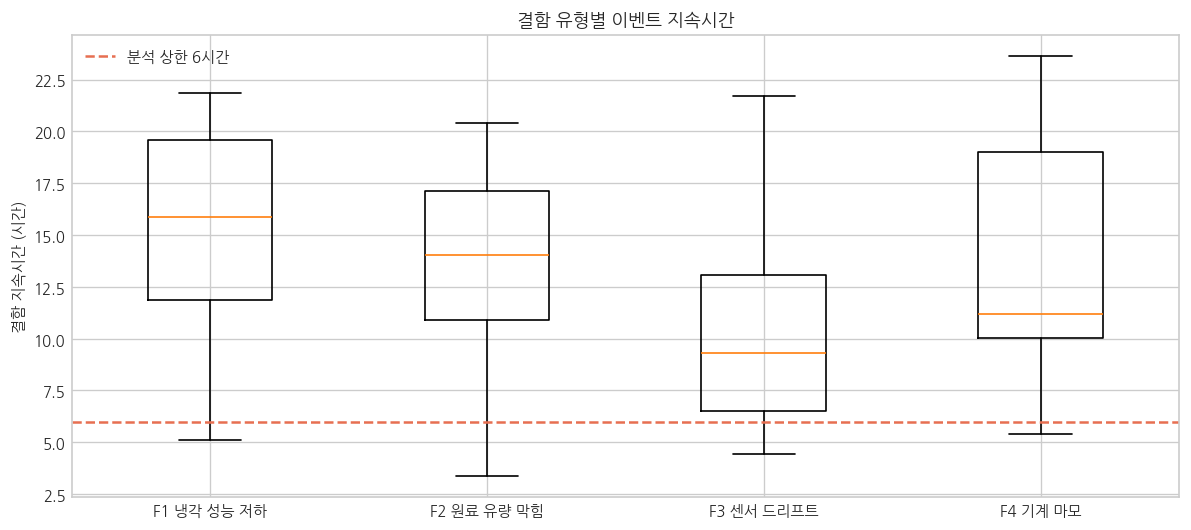

In [2]:
df["segment_start"] = df.groupby("reactor_id")["fault_type"].transform(lambda s:s.ne(s.shift()))
df["segment_id"] = df.groupby("reactor_id")["segment_start"].cumsum()
segments = (df.groupby(["reactor_id","segment_id"],as_index=False)
            .agg(start=("timestamp","min"),end=("timestamp","max"),fault_type=("fault_type","first"),
                 operating_regime=("operating_regime","first"),duration_min=("timestamp","size")))
events = segments[segments["fault_type"].ne(0)].copy().reset_index(drop=True)
events["event_id"] = np.arange(1,len(events)+1)
events["fault_name"] = events["fault_type"].map(fault_names)

summary = events.groupby("fault_name")["duration_min"].agg(event_count="count",min_min="min",median_min="median",max_min="max")
print(summary.to_string())

fig,ax=plt.subplots(figsize=(10,4.5))
data=[events.loc[events["fault_type"].eq(f),"duration_min"].div(60) for f in [1,2,3,4]]
ax.boxplot(data,tick_labels=[fault_names[f] for f in [1,2,3,4]],showfliers=True)
ax.axhline(6,color="#e76f51",linestyle="--",label="분석 상한 6시간")
ax.set_ylabel("결함 지속시간 (시간)"); ax.set_title("결함 유형별 이벤트 지속시간"); ax.legend()
plt.tight_layout(); plt.show()


## 2. 시작 시점 정렬과 표준화

각 이벤트의 시작 시각을 0으로 맞추고 `-2시간 ~ +6시간` 구간을 추출합니다. 센서 단위 차이를 제거하기 위해 시작 전 2시간의 중앙값과 IQR로 표준화합니다.

`표준화 변화 = (센서값 - 시작 전 중앙값) / 시작 전 IQR`

결함 종료 후의 값은 해당 이벤트 패턴 계산에서 제외합니다.


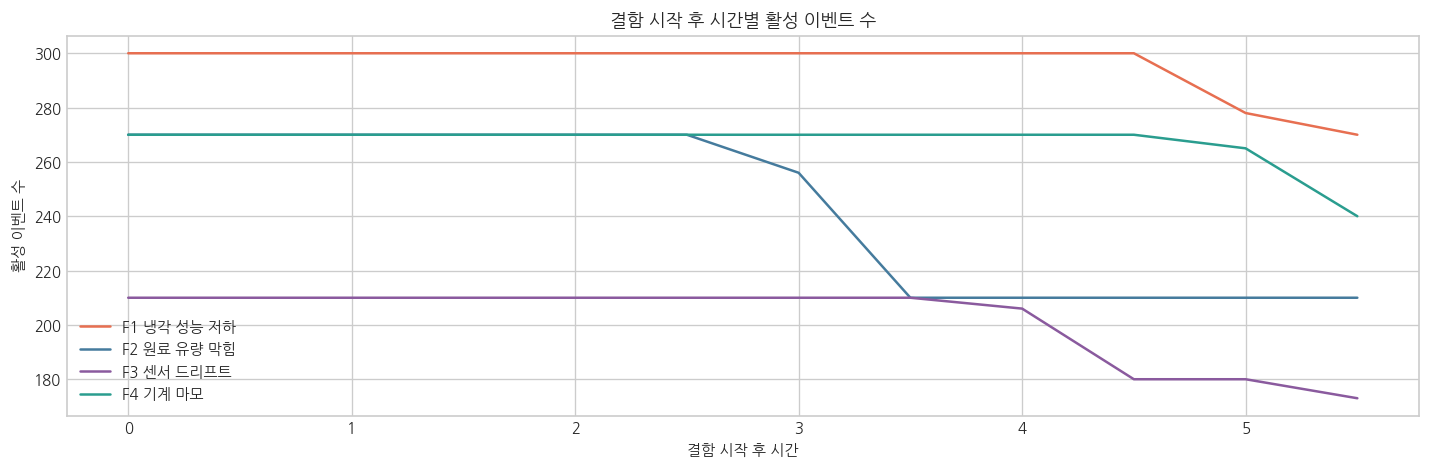

In [3]:
windows=[]
for event in events.itertuples():
    w=df[df["reactor_id"].eq(event.reactor_id)&
         df["timestamp"].ge(event.start-pd.Timedelta(hours=2))&
         df["timestamp"].lt(event.start+pd.Timedelta(hours=6))].copy()
    w["event_id"]=event.event_id; w["event_fault_type"]=event.fault_type; w["event_start"]=event.start
    w["relative_min"]=(w["timestamp"]-event.start).dt.total_seconds().div(60).astype(int)
    w["fault_active"] = w["fault_type"].eq(event.fault_type) & w["relative_min"].ge(0)
    pre=w[w["relative_min"].lt(0)]
    med=pre[sensor_cols].median(); iqr=(pre[sensor_cols].quantile(.75)-pre[sensor_cols].quantile(.25)).replace(0,np.nan)
    for c in sensor_cols:
        w[f"{c}__norm"]=(w[c]-med[c])/iqr[c]
        w[f"{c}__pattern"]=w[f"{c}__norm"].where(w["relative_min"].lt(0)|w["fault_active"])
    windows.append(w)

event_windows=pd.concat(windows,ignore_index=True)
event_windows["relative_30min"]=(np.floor(event_windows["relative_min"]/30)*30).astype(int)

active=(event_windows[event_windows["relative_min"].ge(0)]
        .groupby(["event_fault_type","relative_30min"])["fault_active"].sum().unstack(0))
fig,ax=plt.subplots(figsize=(12,4))
for f in [1,2,3,4]: ax.plot(active.index/60,active[f],label=fault_names[f],color=colors[f])
ax.set_title("결함 시작 후 시간별 활성 이벤트 수"); ax.set_xlabel("결함 시작 후 시간"); ax.set_ylabel("활성 이벤트 수"); ax.legend()
plt.tight_layout(); plt.show()


## 3. 결함 유형별 센서 반응 궤적

30분 단위 이벤트 중앙값을 다시 결함 유형별로 요약합니다. 선은 이벤트 중앙값, 음영은 이벤트 간 25~75% 범위입니다. 세로선 0은 결함 시작 시점입니다.


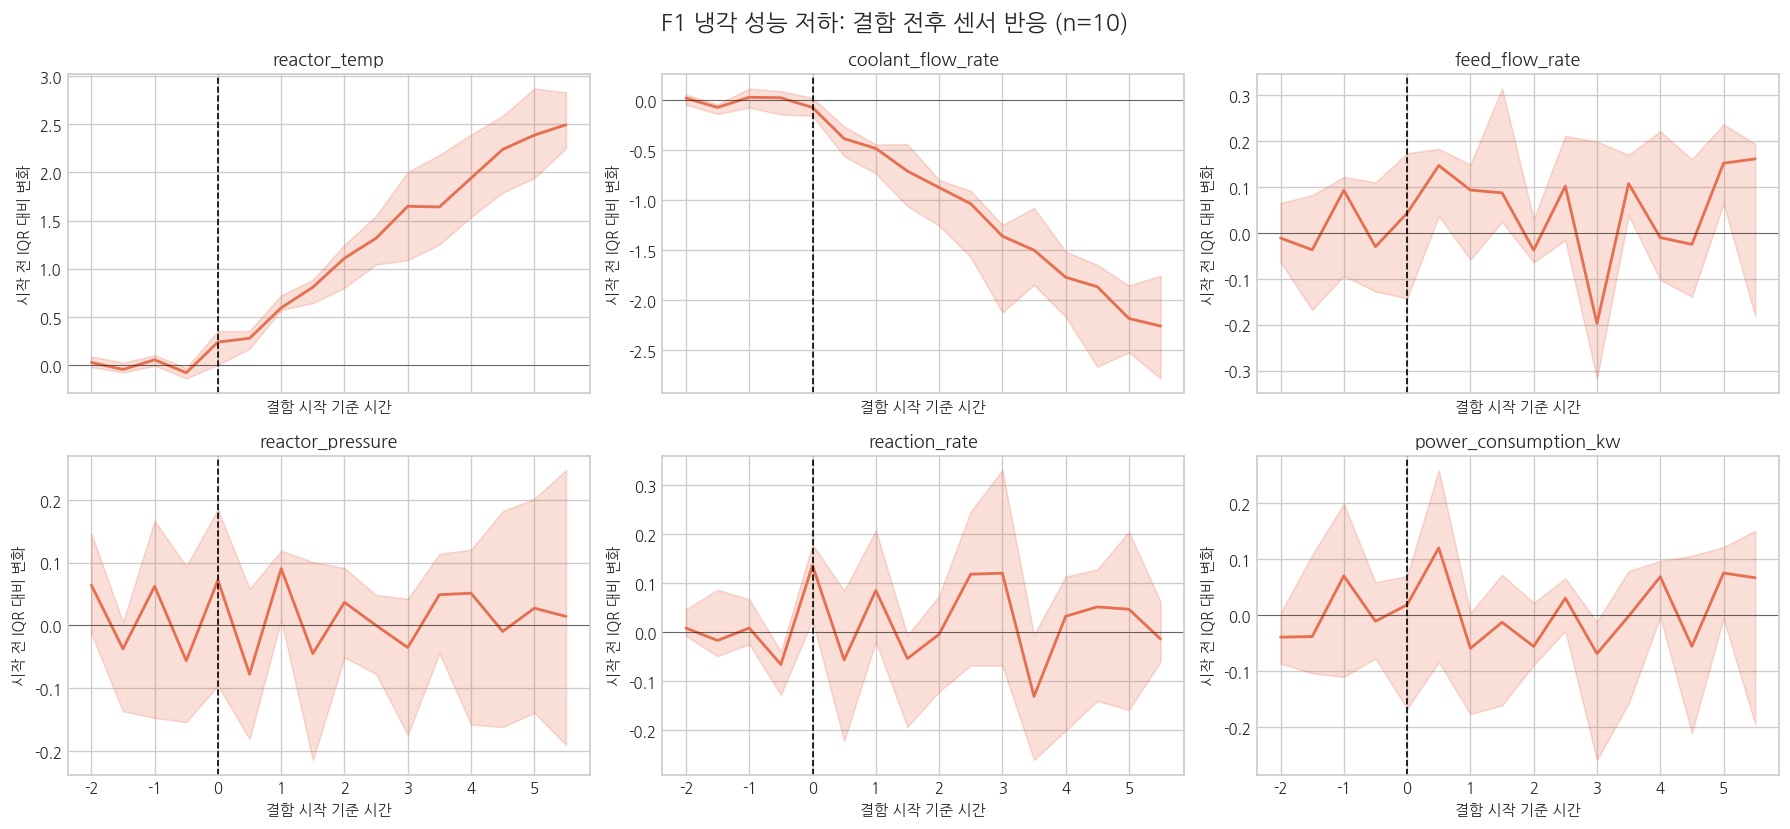

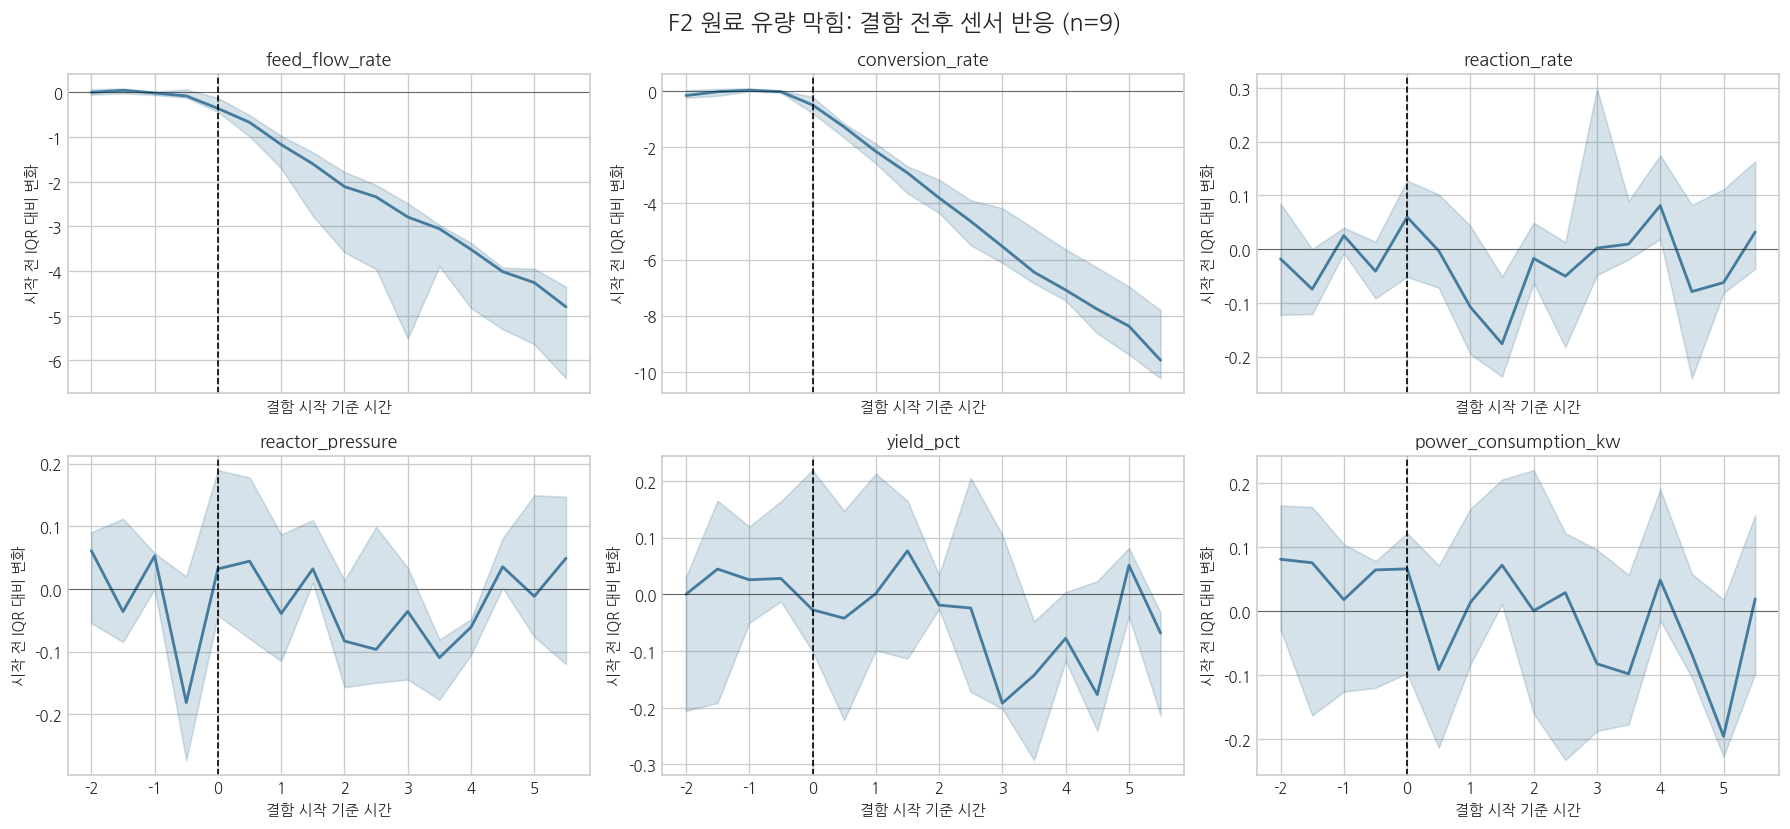

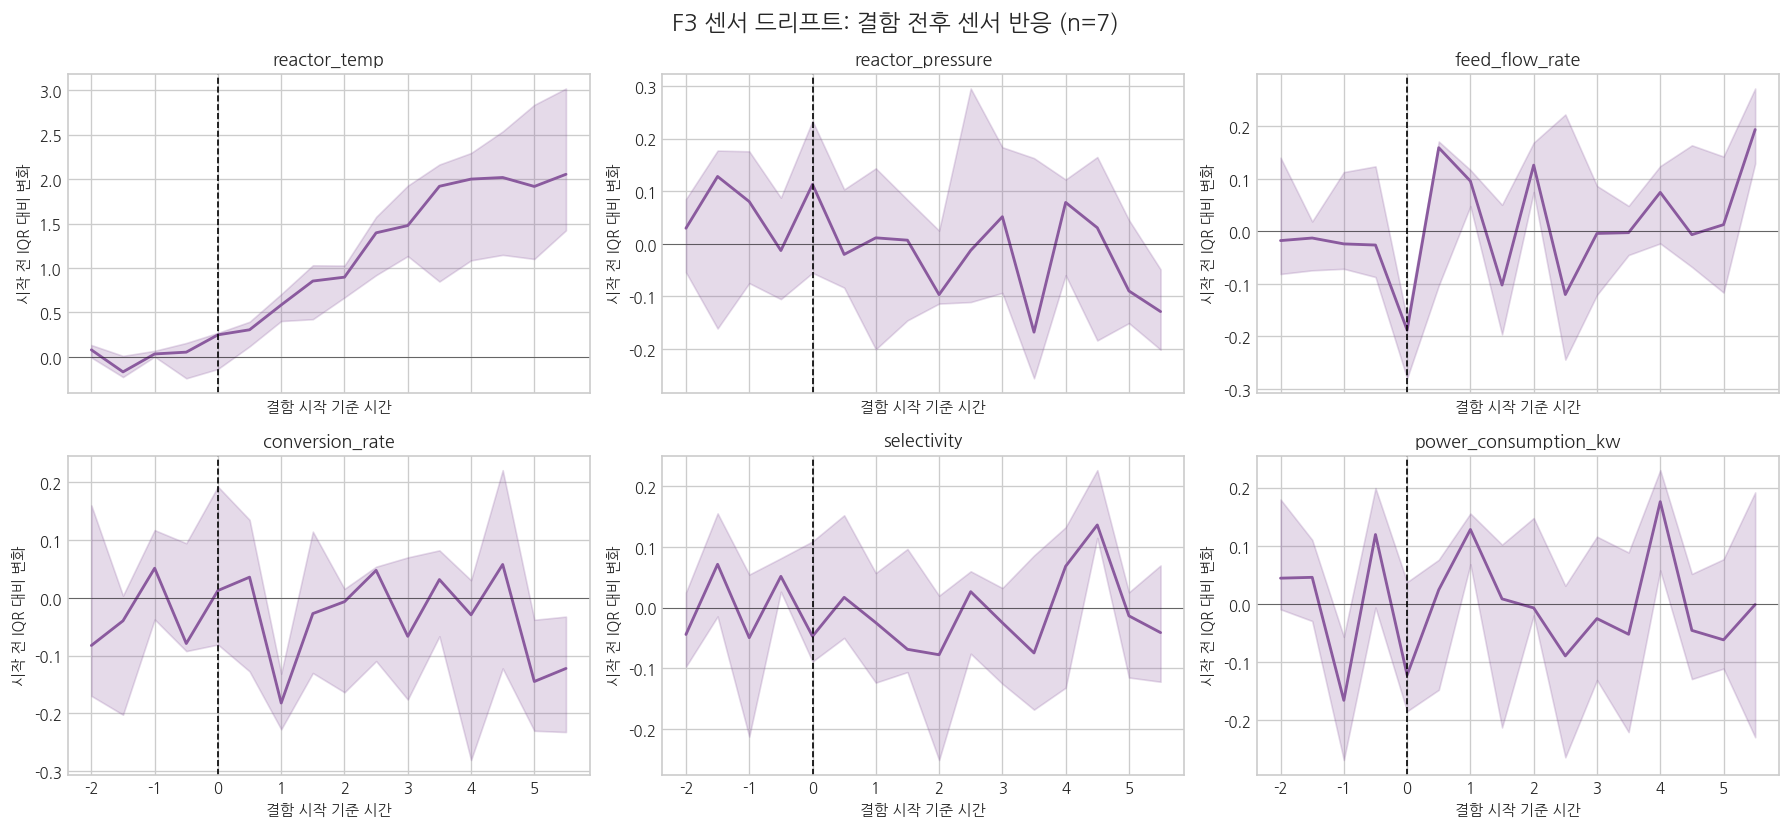

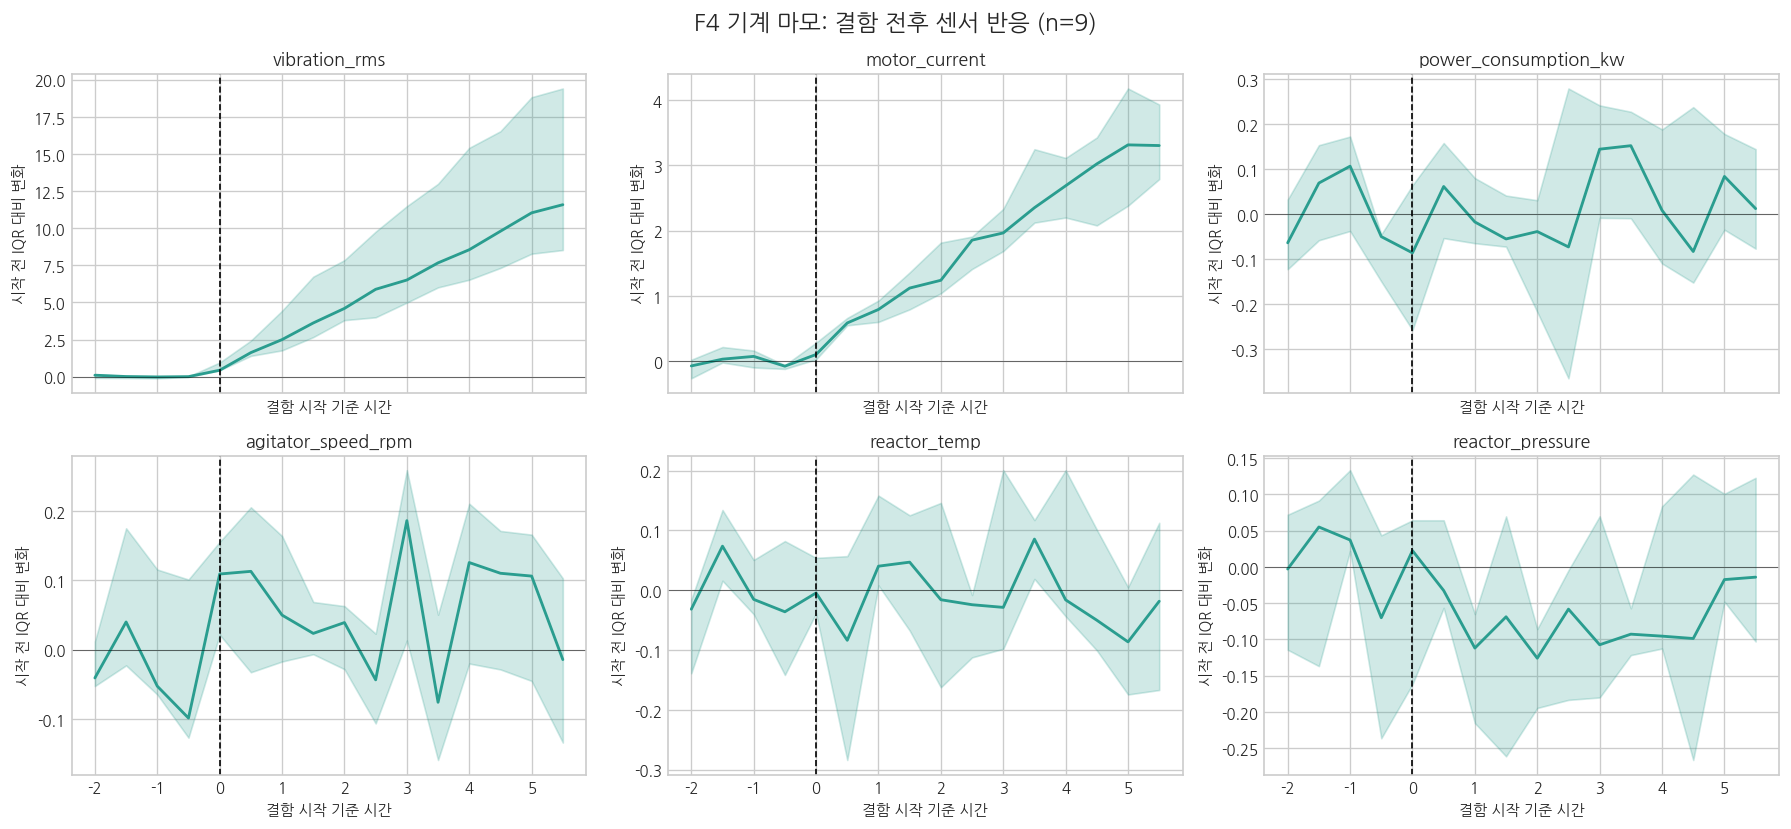

In [4]:
plot_sensors={
1:["reactor_temp","coolant_flow_rate","feed_flow_rate","reactor_pressure","reaction_rate","power_consumption_kw"],
2:["feed_flow_rate","conversion_rate","reaction_rate","reactor_pressure","yield_pct","power_consumption_kw"],
3:["reactor_temp","reactor_pressure","feed_flow_rate","conversion_rate","selectivity","power_consumption_kw"],
4:["vibration_rms","motor_current","power_consumption_kw","agitator_speed_rpm","reactor_temp","reactor_pressure"]}

for f,cols in plot_sensors.items():
    sub=event_windows[event_windows["event_fault_type"].eq(f)]
    fig,axes=plt.subplots(2,3,figsize=(15,7),sharex=True)
    for ax,c in zip(axes.flat,cols):
        pe=(sub.groupby(["event_id","relative_30min"])[f"{c}__pattern"].median().reset_index())
        s=pe.groupby("relative_30min")[f"{c}__pattern"].agg(median="median",q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75),n="count")
        x=s.index.to_numpy()/60
        ax.plot(x,s["median"],color=colors[f],linewidth=1.7); ax.fill_between(x,s["q25"],s["q75"],color=colors[f],alpha=.22)
        ax.axvline(0,color="black",linestyle="--",linewidth=1); ax.axhline(0,color="black",linewidth=.6,alpha=.5)
        ax.set_title(c); ax.set_ylabel("시작 전 IQR 대비 변화"); ax.set_xlabel("결함 시작 기준 시간")
    fig.suptitle(f"{fault_names[f]}: 결함 전후 센서 반응 (n={sub['event_id'].nunique()})",fontsize=14)
    plt.tight_layout(); plt.show()


## 4. 발생 후 구간별 변화 크기

결함 활성 상태인 관측치만 사용하여 시작 후 `0~1시간`, `1~3시간`, `3~6시간`의 중앙 변화를 계산합니다. 값의 절댓값이 클수록 시작 전 정상 변동 범위에 비해 변화가 큽니다.


결함 발생 후 첫 1시간 중앙 변화
sensor      agitator_speed_rpm  conversion_rate  coolant_flow_rate  feed_flow_rate  motor_current  power_consumption_kw  reaction_rate  reactor_pressure  reactor_temp  selectivity  vibration_rms  yield_pct
fault_type                                                                                                                                                                                                   
1                       -0.000           -0.040             -0.180           0.120         -0.000                -0.020          0.020             0.010         0.250       -0.080          0.000     -0.010
2                       -0.050           -0.810             -0.090          -0.480         -0.040                 0.020          0.070             0.030         0.000        0.070         -0.010     -0.010
3                       -0.130           -0.010             -0.020          -0.050         -0.030                 0.020         -0.020            -0.010    

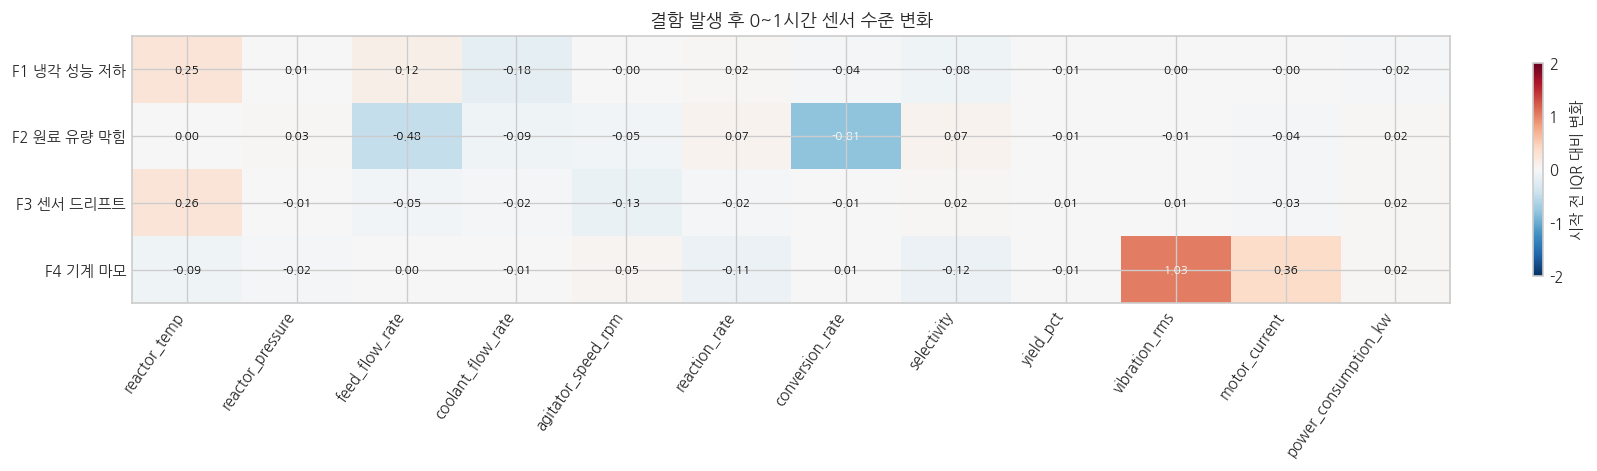

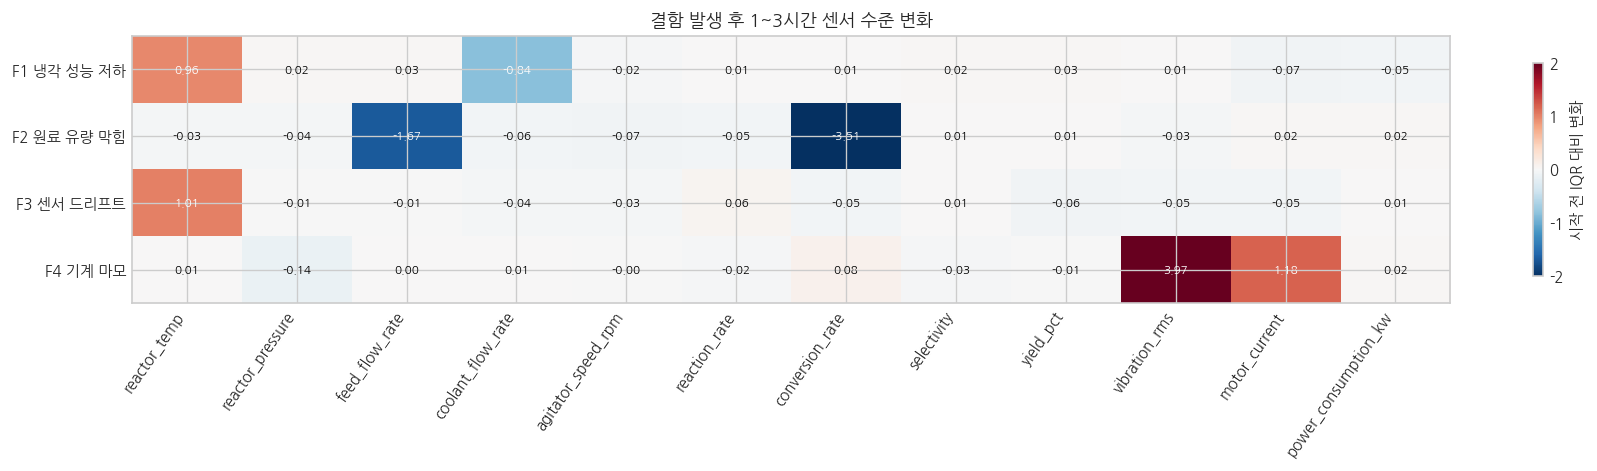

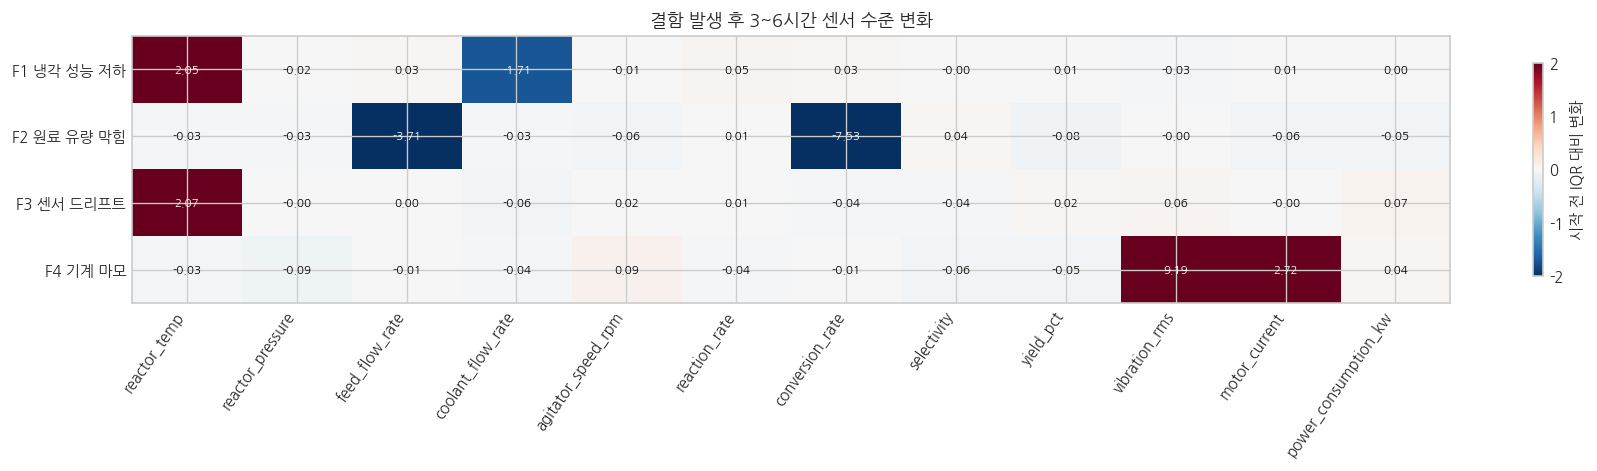

In [5]:
periods={"0~1시간":(0,60),"1~3시간":(60,180),"3~6시간":(180,360)}
rows=[]
for event_id,g in event_windows.groupby("event_id"):
    f=int(g["event_fault_type"].iloc[0])
    for label,(lo,hi) in periods.items():
        part=g[g["relative_min"].ge(lo)&g["relative_min"].lt(hi)&g["fault_active"]]
        if len(part)<30: continue
        for c in sensor_cols:
            rows.append({"event_id":event_id,"fault_type":f,"period":label,"sensor":c,"shift":part[f"{c}__norm"].median()})
period_features=pd.DataFrame(rows)

for label in periods:
    matrix=(period_features[period_features["period"].eq(label)].groupby(["fault_type","sensor"])["shift"].median()
            .unstack("sensor").reindex(index=[1,2,3,4],columns=sensor_cols))
    fig,ax=plt.subplots(figsize=(15,4)); im=ax.imshow(matrix,aspect="auto",cmap="RdBu_r",vmin=-2,vmax=2)
    ax.set_yticks(range(4),[fault_names[f] for f in [1,2,3,4]])
    ax.set_xticks(range(len(sensor_cols)),sensor_cols,rotation=55,ha="right")
    ax.set_title(f"결함 발생 후 {label} 센서 수준 변화")
    for i in range(4):
        for j in range(len(sensor_cols)):
            v=matrix.iloc[i,j]; ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7,color="white" if abs(v)>.8 else "black")
    fig.colorbar(im,ax=ax,shrink=.8,label="시작 전 IQR 대비 변화"); plt.tight_layout(); plt.show()

first_hour=(period_features[period_features["period"].eq("0~1시간")].groupby(["fault_type","sensor"])["shift"].median())
print("결함 발생 후 첫 1시간 중앙 변화")
print(first_hour.unstack("sensor").round(2).to_string())


## 5. 첫 1시간 변화의 이벤트 간 일관성

중앙값이 커도 일부 이벤트에서만 나타나면 운영 임계값으로 쓰기 어렵습니다. 각 결함 유형에서 변화 방향이 반복되는지 확인합니다.


 fault_name               sensor  events  median_shift  positive_share    q25    q75
F1 냉각 성능 저하         reactor_temp      10         0.250           0.900  0.130  0.290
F1 냉각 성능 저하    coolant_flow_rate      10        -0.180           0.000 -0.360 -0.170
F1 냉각 성능 저하       feed_flow_rate      10         0.120           0.700 -0.040  0.200
F1 냉각 성능 저하          selectivity      10        -0.080           0.400 -0.180  0.030
F1 냉각 성능 저하      conversion_rate      10        -0.040           0.300 -0.100  0.040
F1 냉각 성능 저하 power_consumption_kw      10        -0.020           0.400 -0.030  0.050
F2 원료 유량 막힘      conversion_rate       9        -0.810           0.000 -0.990 -0.660
F2 원료 유량 막힘       feed_flow_rate       9        -0.480           0.000 -0.690 -0.420
F2 원료 유량 막힘    coolant_flow_rate       9        -0.090           0.330 -0.190  0.090
F2 원료 유량 막힘        reaction_rate       9         0.070           0.560 -0.090  0.120
F2 원료 유량 막힘          selectivity       9         0.070           

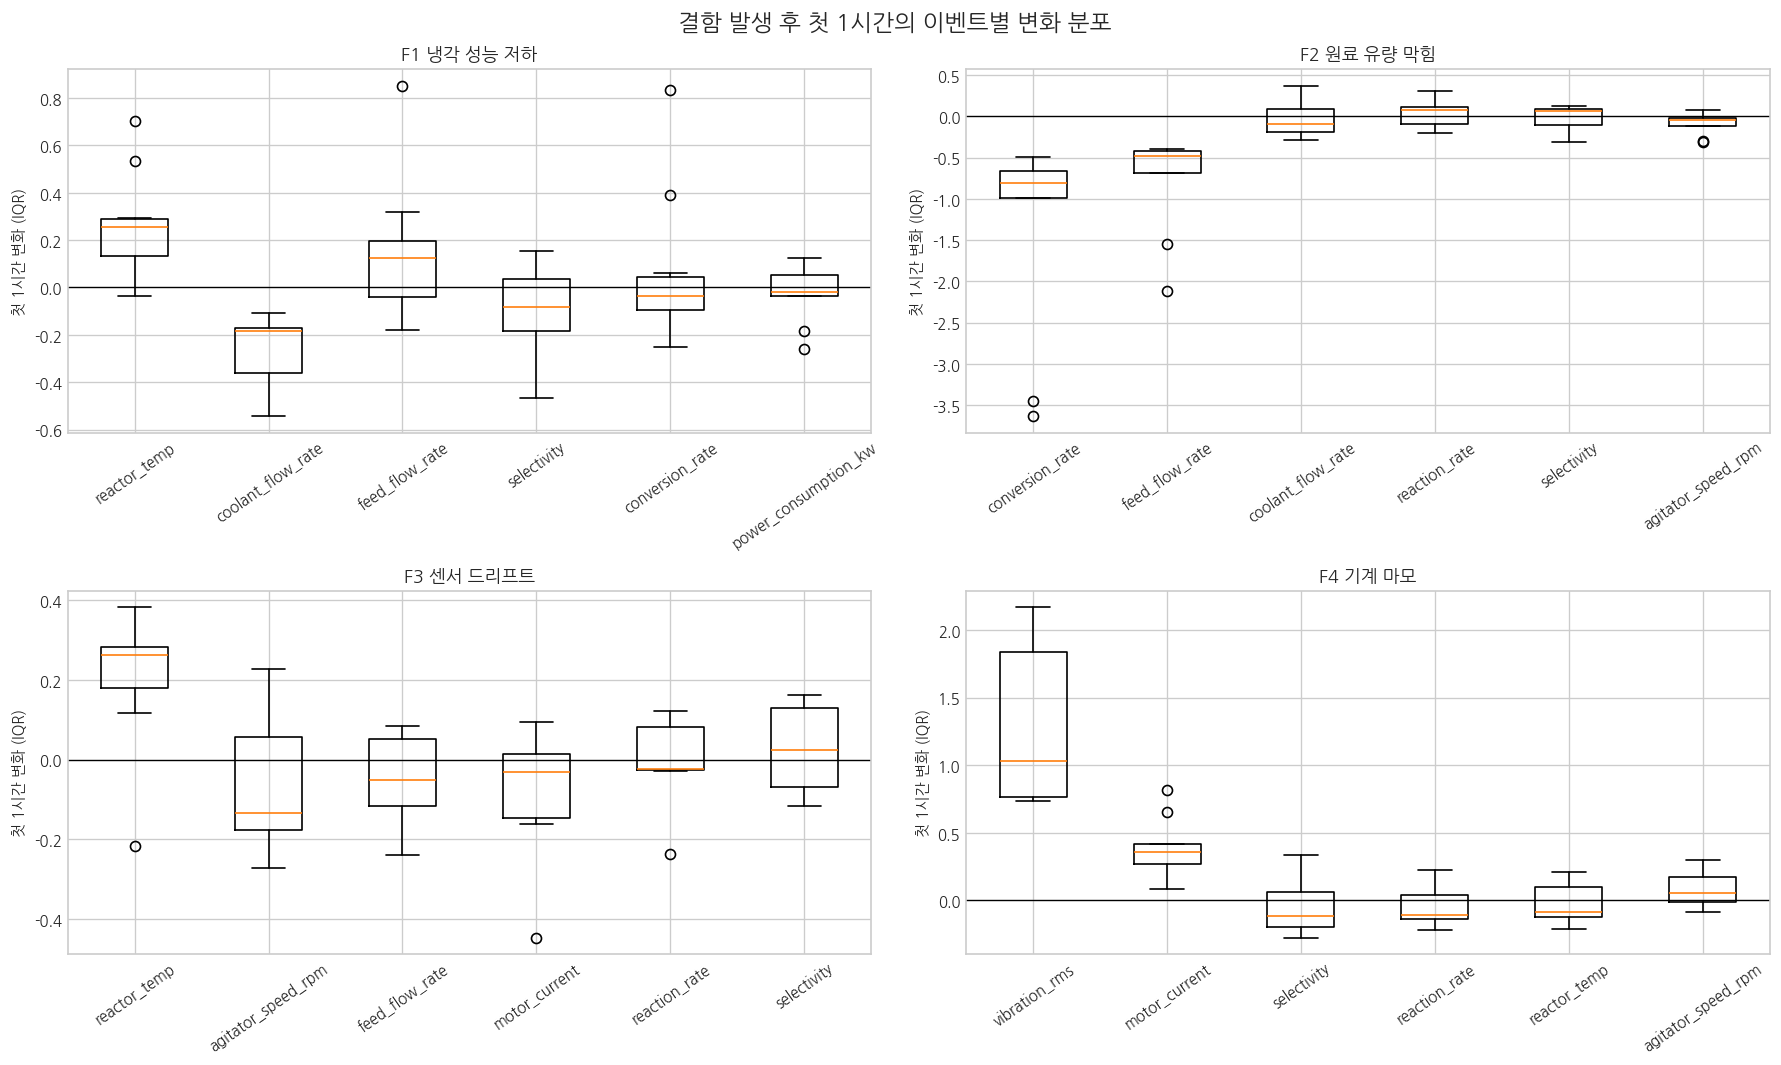

In [6]:
fh=period_features[period_features["period"].eq("0~1시간")].copy()
cons=(fh.assign(positive=lambda x:x["shift"].gt(0)).groupby(["fault_type","sensor"])
      .agg(events=("event_id","count"),median_shift=("shift","median"),positive_share=("positive","mean"),q25=("shift",lambda x:x.quantile(.25)),q75=("shift",lambda x:x.quantile(.75))).reset_index())
tops=[]
for f in [1,2,3,4]:
    x=cons[cons["fault_type"].eq(f)].copy(); x["strength"]=x["median_shift"].abs(); x=x.nlargest(6,"strength"); x.insert(1,"fault_name",fault_names[f]); tops.append(x)
top=pd.concat(tops)
print(top[["fault_name","sensor","events","median_shift","positive_share","q25","q75"]].round(2).to_string(index=False))

strong=cons[cons["median_shift"].abs().ge(.5)]
consistent=strong[strong["positive_share"].ge(.8)|strong["positive_share"].le(.2)]
print(f"\n첫 1시간 |변화| >= 0.5 IQR: {len(strong)} / {len(cons)} 조합")
print(f"그중 방향이 80% 이상 일치: {len(consistent)}개")

fig,axes=plt.subplots(2,2,figsize=(15,9))
for ax,f in zip(axes.flat,[1,2,3,4]):
    part=fh[fh["fault_type"].eq(f)]; order=part.groupby("sensor")["shift"].median().sort_values(key=abs,ascending=False).index[:6]
    vals=[part.loc[part["sensor"].eq(c),"shift"].dropna() for c in order]
    ax.boxplot(vals,tick_labels=order,showfliers=True); ax.axhline(0,color="black",linewidth=.8); ax.set_title(fault_names[f]); ax.set_ylabel("첫 1시간 변화 (IQR)"); ax.tick_params(axis="x",rotation=35)
plt.suptitle("결함 발생 후 첫 1시간의 이벤트별 변화 분포",fontsize=14); plt.tight_layout(); plt.show()


## 6. 결론

결함 시작 전에는 뚜렷한 전조가 거의 없었지만, 시작 후에는 유형별 패턴이 나타납니다.

- **F1 냉각 성능 저하:** 반응기 온도가 상승하고 냉각수 유량이 감소합니다. 냉각 계통 이상이라는 정의와 일치하는 방향입니다.
- **F2 원료 유량 막힘:** 원료 유량과 전환율이 감소합니다. 특히 전환율 변화가 첫 1시간부터 큽니다.
- **F3 센서 드리프트:** 반응기 온도 측정값이 변하지만 다른 결함보다 단일 센서만으로 구분하기 어렵습니다. 센서 간 물리적 관계의 불일치를 활용하는 접근이 필요합니다.
- **F4 기계 마모:** 진동 RMS와 모터 전류가 상승합니다. 첫 1시간부터 가장 구분하기 쉬운 패턴 중 하나입니다.
- **전력 소비량:** 첫 1시간의 전력 변화는 네 결함 모두 상대적으로 작습니다. 전력 단독 임계값보다 진동·전류·유량·온도와 결합해야 합니다.

### 모델링 시사점

1. 이 데이터에는 장시간 조기예측보다 **결함 발생 직후 탐지** 문제가 더 적합합니다.
2. 결함 여부 탐지와 결함 유형 분류를 2단계로 분리할 수 있습니다.
3. 특징은 현재값뿐 아니라 30분·60분 이동평균, 이동표준편차, 기준선 대비 변화량을 사용합니다.
4. 동일 이벤트가 학습과 평가에 동시에 들어가지 않도록 이벤트 또는 시간 단위로 분할해야 합니다.
5. 탐지 성능은 정확도뿐 아니라 이벤트별 탐지율, 오탐 수, 시작 후 탐지 지연시간으로 평가해야 합니다.
